# Adim 6.2: Makine Ogrenmesi - Random Forest Regressor

Bu notebook'ta, ozellik muhendisligi tamamlanmis NYC Taxi verilerini kullanarak **Random Forest Regressor** modelini egitecegiz.

### Bu Adimda Yapilacaklar:
1. **Veri Yukleme:** feature(Gold) katmanindan (Step 5) verilerin okunmasi.
2. **Ozellik Hazirligi:** Verilerin vektor formuna getirilmesi ve Train/Test ayrimi.
3. **MLflow Entegrasyonu:** Tum parametre ve metriklerin loglanmasi.
4. **Model Degerlendirme:** RMSE, MAE, R² ve Residual analizi.
5. **Ozellik Onemi:** Feature Importance analizi.

In [1]:
from pyspark.sql import SparkSession
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import RandomForestRegressor
from pyspark.ml.evaluation import RegressionEvaluator
import mlflow
import mlflow.spark
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Spark Oturumunu Baslat (Delta destegi ile)
spark = SparkSession.builder \
    .appName("NYC-Taxi-ModelTraining-RF") \
    .config("spark.jars.packages", "io.delta:delta-spark_2.12:3.1.0") \
    .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension") \
    .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog") \
    .getOrCreate()

# MLflow Ayarlari
mlflow.set_tracking_uri("http://mlflow-server:5001")
mlflow.set_experiment("Taxi_Fare_Prediction")

print("Spark ve MLflow Hazir.")

Spark ve MLflow Hazir.


## 1. Veri Okuma
Adim 5'te kaydettigimiz Gold tablosunu yukluyoruz.

In [2]:
gold_path = "/home/jovyan/work/data/delta/features"
df = spark.read.format("delta").load(gold_path)

print(f"Egitim icin yuklenen toplam kayit sayisi: {df.count()}")
df.printSchema()

Egitim icin yuklenen toplam kayit sayisi: 1798960
root
 |-- VendorID: integer (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: long (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: long (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: integer (nullable = true)
 |-- DOLocationID: integer (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- Airport_fee: double (nullable = true)
 |-- trip_duration_min: double (nullable = true)
 |-- average_speed: double 

## 2. Ozelliklerin Vektorlestirilmesi
Spark ML algoritmalari, girdi ozelliklerini tek bir `features` sutununda vektor olarak bekler.

In [3]:
# Modelde kullanilacak ozellikler
feature_cols = [
    "trip_distance", 
    "trip_duration_min", 
    "average_speed", 
    "pickup_hour", 
    "day_of_week", 
    "is_airport_trip", 
    "is_rush_hour"
]

assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")
final_df = assembler.transform(df).select("features", "total_amount")

# Veriyi %80 Egitim, %20 Doğrulama olarak ayiriyoruz
train_df, validation_df = final_df.randomSplit([0.8, 0.2], seed=42)

print(f"Egitim seti: {train_df.count()} kayit")
print(f"Doğrulama seti: {validation_df.count()} kayit")

Egitim seti: 1439385 kayit
Doğrulama seti: 359575 kayit


## 3. Random Forest Modeli Egitimi ve MLflow Kaydi

In [4]:
with mlflow.start_run(run_name="RF_Regressor_Final"):
    # 1. Model Parametreleri
    num_trees = 50
    max_depth = 10
    
    rf = RandomForestRegressor(
        featuresCol="features", 
        labelCol="total_amount", 
        numTrees=num_trees, 
        maxDepth=max_depth,
        seed=42
    )
    
    # 2. Modeli Egit
    print("Random Forest Modeli egitiliyor, lutfen bekleyin...")
    model = rf.fit(train_df)
    
    # 3. Tahmin Yap
    predictions = model.transform(validation_df)
    
    # 4. Metrikleri Hesapla
    evaluator_rmse = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="rmse")
    evaluator_mae = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="mae")
    evaluator_r2 = RegressionEvaluator(labelCol="total_amount", predictionCol="prediction", metricName="r2")
    
    rmse = evaluator_rmse.evaluate(predictions)
    mae = evaluator_mae.evaluate(predictions)
    r2 = evaluator_r2.evaluate(predictions)
    
    # 5. MLflow'a Logla
    mlflow.log_param("model_type", "RandomForestRegressor")
    mlflow.log_param("numTrees", num_trees)
    mlflow.log_param("maxDepth", max_depth)
    mlflow.log_metric("rmse", rmse)
    mlflow.log_metric("mae", mae)
    mlflow.log_metric("r2", r2)
    
    mlflow.spark.log_model(model, "rf_model")
    
    print(f"Model Basariyla Egitildi.")
    print(f"RMSE: {rmse:.2f}")
    print(f"MAE: {mae:.2f}")
    print(f"R2 Score: {r2:.2f}")

Random Forest Modeli egitiliyor, lutfen bekleyin...
Model Basariyla Egitildi.
RMSE: 6.98
MAE: 2.91
R2 Score: 0.90
🏃 View run RF_Regressor_Final at: http://mlflow-server:5001/#/experiments/1/runs/8f7c180e70a4480a9323e57866d55a7b
🧪 View experiment at: http://mlflow-server:5001/#/experiments/1


## 4. Ozellik Onemi (Feature Importance)
Hangi ozelligin tahmin uzerinde ne kadar etkili oldugunu gorelim.

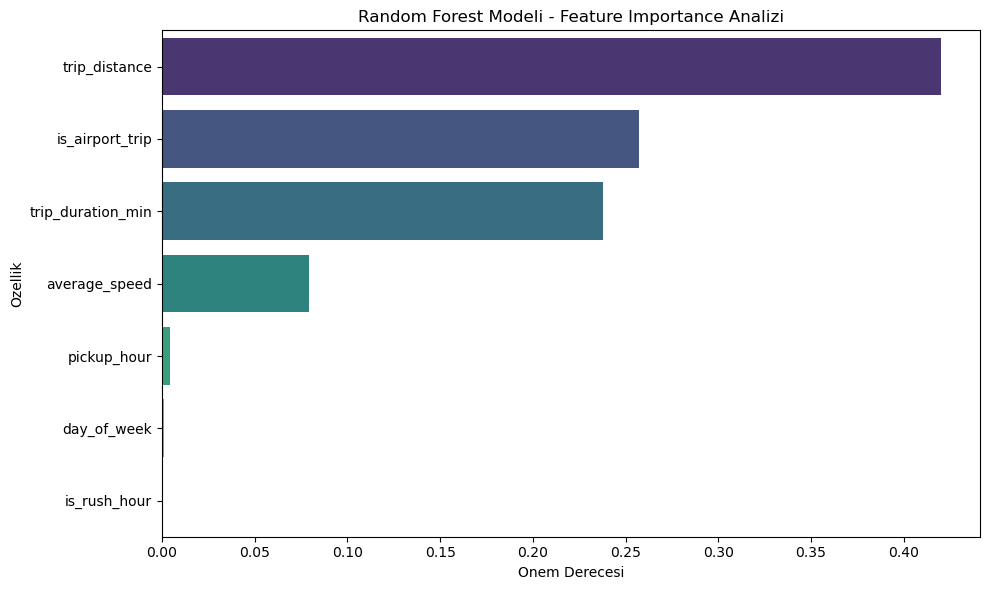

In [5]:
importance = model.featureImportances.toArray()
feat_imp_df = pd.DataFrame({'Feature': feature_cols, 'Importance': importance})
feat_imp_df = feat_imp_df.sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feat_imp_df, hue='Feature', palette='viridis', legend=False)
plt.title('Random Forest Modeli - Feature Importance Analizi')
plt.xlabel('Onem Derecesi')
plt.ylabel('Ozellik')
plt.tight_layout()
plt.show()

## 5. Gercek vs Tahmin & Residual Analizi

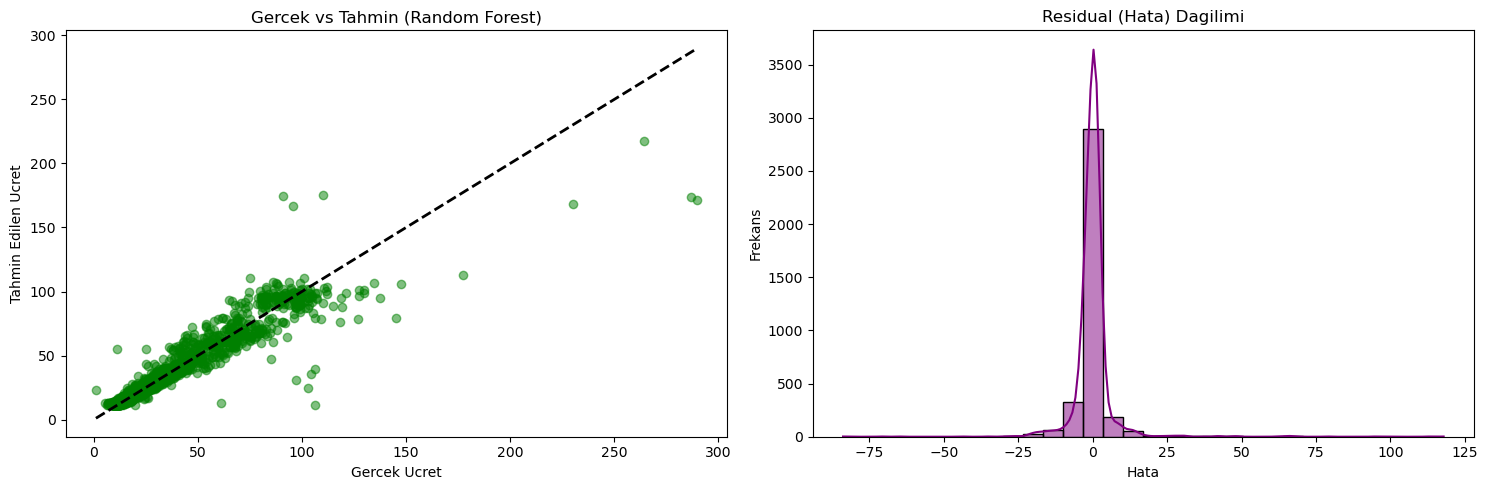

In [6]:
# Analiz icin bir orneklem alalim
preds_pd = predictions.select("total_amount", "prediction").sample(0.01).toPandas()
preds_pd['residual'] = preds_pd['total_amount'] - preds_pd['prediction']

plt.figure(figsize=(15, 5))

# 1. Gercek vs Tahmin Scatter Plot
plt.subplot(1, 2, 1)
plt.scatter(preds_pd['total_amount'], preds_pd['prediction'], alpha=0.5, color='green')
plt.plot([preds_pd['total_amount'].min(), preds_pd['total_amount'].max()], 
         [preds_pd['total_amount'].min(), preds_pd['total_amount'].max()], 'k--', lw=2)
plt.xlabel('Gercek Ucret')
plt.ylabel('Tahmin Edilen Ucret')
plt.title('Gercek vs Tahmin (Random Forest)')

# 2. Residual Dagilimi
plt.subplot(1, 2, 2)
sns.histplot(preds_pd['residual'], bins=30, kde=True, color='purple')
plt.title('Residual (Hata) Dagilimi')
plt.xlabel('Hata')
plt.ylabel('Frekans')

plt.tight_layout()
plt.show()